# CREDA sobre el toyset — cómo se entrena

Este cuaderno es un **ejemplo completo de entrenamiento de CREDA**, de punta a
punta y con todo a la vista: los datos, el modelo, la pérdida, el optimizador,
los bucles de entrenamiento, la evaluación y las gráficas.

- **Una sola arquitectura**: `Linear → ReLU → BatchNorm1d` como encoder (el `MLP`
  de una capa del toyset) y una cabeza `Linear` que clasifica tres clases.
- **Las tres familias** del toyset: `lunas`, `toroide` y `rollo`. Cada una tiene
  un dominio **fuente** con etiquetas y un dominio **blanco** corrido (una
  rotación que preserva la covarianza más una traslación), cuyas etiquetas el
  entrenamiento **nunca** lee.
- **Dos versiones del método**, elegidas con `VERSION` en un `if/else` de dos
  diccionarios:
  - `"v2"` (por defecto): el protocolo actual del toyset, en dos fases.
  - `"v01"`: el objetivo de la publicación previa, un único entrenamiento conjunto.

Corre en CPU, no descarga nada y no escribe nada en disco: los modelos, las
historias y la figura quedan en memoria.

> **Los presupuestos son didácticos, no ajustados.** Las épocas, las tasas de
> aprendizaje y los tamaños de lote de abajo son valores modestos para que el
> cuaderno termine en poco tiempo. No salen de ninguna búsqueda de
> hiperparámetros y no garantizan convergencia: los números que imprima este
> cuaderno son los de **esta** corrida, no resultados publicados.

## Dónde está el repositorio

La primera celda de código es la misma en todos los cuadernos que puede correr
un trabajo remoto, copiada byte por byte. Abierto en tu máquina, `ROOT` es el
directorio dos niveles arriba del cuaderno; lanzado por un runner, `ROOT` es el
clon fijado en `FORGE_CLONE_ROOT`, verificado contra `FORGE_CLONE_COMMIT`.

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()

## Las piezas que se reutilizan

Nada de lo que define el método se reescribe acá. Se importa del código de
producción:

| pieza | de dónde | para qué |
| --- | --- | --- |
| `CREDALoss` | `CREDA.models` | el término de adaptación |
| `creda_ramp` | `CREDA.schedules` | la rampa del coeficiente en `v01` |
| `get_eta` | `CREDA.training_pipeline` | el decaimiento de la tasa de aprendizaje en `v01` |
| `clone_for_target`, `parameter_distance` | `CREDA.two_phase` | la copia única fuente → blanco en `v2` y cuánto se alejó |
| `FAMILIAS`, `datos_semilla`, `MLP` | `CREDA.toy_experiment` | las tres familias, sus particiones y el encoder |
| `perdida_fuente`, `sigma_de_la_fuente`, `clases_efectivas` | `CREDA.toy_experiment` | la CE normalizada de la fase 1, el ancho de banda congelado y un monitor sin etiquetas |
| `TrajectoryRecorder`, `adaptation_gif`, `confidence_walks`, `confidence_walk_gif` | `CREDA.tutorial_visuals` | las fotos de la trayectoria y las dos animaciones, en memoria |

Lo que sí está escrito acá son los **bucles**: así se ve qué parámetros mueve
cada optimizador y qué entra en cada objetivo.

In [2]:
import sys
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display

from CREDA.models import CREDALoss
from CREDA.schedules import creda_ramp
from CREDA.training_pipeline import get_eta
from CREDA.two_phase import clone_for_target, parameter_distance
from CREDA.toy_experiment import (
    CLASES, FAMILIAS, MLP, clases_efectivas, datos_semilla, perdida_fuente,
    sigma_de_la_fuente)
from CREDA.tutorial_visuals import (
    TrajectoryRecorder, adaptation_gif, confidence_walk_gif, confidence_walks)

## Parámetros

`VERSION` elige el método. `ADJUSTMENTS` sobreescribe claves del diccionario
elegido sin editarlo — por ejemplo `{"source_epochs": 3}` para una pasada
rápida — y una clave que el diccionario no tiene se rechaza en vez de ignorarse
en silencio. La celda lleva la etiqueta `parameters`, así que papermill o un
runner pueden inyectar otros valores.

`FRAMES` y `WALK_STEPS` no tocan el entrenamiento: dicen cuántas fotos de la
trayectoria guarda el GIF de la adaptación (más la del inicio) y en cuántos
pasos se recorre la caminata del peso `w`.

In [3]:
VERSION = "v2"     # "v2": protocolo actual (por defecto) · "v01": publicación previa
ADJUSTMENTS = {}   # p. ej. {"source_epochs": 3, "adaptation_epochs": 2}
SEED = 0
FRAMES = 12        # fotos de la trayectoria para el GIF de la adaptación (más la inicial)
WALK_STEPS = 40    # pasos del barrido de la caminata del peso w

## Las dos versiones, como dos diccionarios

**`v2` — el protocolo actual del toyset, en dos fases.**

1. **Fase 1, solo la fuente.** El encoder y la cabeza se entrenan con la
   entropía cruzada de la fuente (`perdida_fuente`: la CE dividida por su cota,
   así vive en `[0, 1)`). Se elige la mejor época por el acierto en la
   **validación de la fuente** — la única selección de modelo del cuaderno, y
   usa solo etiquetas de la fuente. Al terminar, encoder y cabeza se
   **congelan**.
2. **La copia.** `clone_for_target` copia el encoder **una sola vez**, buffers
   de BatchNorm incluidos: el encoder del blanco arranca idéntico al de la
   fuente.
3. **El ancho de banda.** `sigma` es la mediana de distancias por pares sobre el
   train **completo de la fuente** en el espacio latente, calculada una vez y
   congelada: nada del blanco puede moverlo.
4. **Fase 2, solo el blanco.** El único parámetro entrenable es el encoder del
   blanco, y el único término es CREDA — con cotas `entropy-cosh`, balance de
   masa por **traza**, ponderación por entropía y bloque cruzado ponderado. **No
   hay CE de la fuente** en este objetivo y **no hay rampa**: el coeficiente es
   1 desde el primer paso.

**`v01` — el objetivo de la publicación previa**, el de `train_creda` en
`CREDA/training_pipeline.py`: **un solo encoder y una sola cabeza** para los dos
dominios, entrenados juntos con

$$\mathcal{L} = \mathrm{CE}_{\text{fuente}} + \lambda(e)\,\mathcal{L}_{\text{CREDA}},
\qquad \lambda(e) = \texttt{creda\_ramp}(e,\ E,\ \delta,\ \text{techo}),$$

con `CREDALoss(sigma='auto', use_entropy_weighting=True,
normalize_by_bounds=False, balance_mass='cardinality')`, sin ponderar el bloque
cruzado, y la tasa de aprendizaje decayendo con `get_eta`.

**Lo que `v01` es y lo que no es.** El objetivo y sus banderas son los
publicados, pero la publicación entrenó ResNets sobre imágenes; acá el mismo
objetivo se aplica a un MLP de una capa sobre el toyset. Por eso la tasa de
aprendizaje base es la del toyset (`1e-2`) y no las `1e-4`/`1e-3` de las
ResNets. El techo de `λ` sí es un valor publicado (`1e-3`): el término CREDA
entra multiplicado por a lo sumo ese número. Si lo subís para ver actuar más a
CREDA, ya no es la configuración publicada. Esto **no reproduce** el experimento de imágenes: es el
mismo objetivo, en otro modelo y otros datos.

Y una advertencia que vale para los dos: cambiar solo las banderas de la pérdida
**no** convierte una versión en la otra. Lo que las separa es el **protocolo**
— qué se entrena, en qué orden, qué se congela y qué entra en cada objetivo —, y
por eso cada versión tiene su propio bucle más abajo.

In [4]:
if VERSION == "v2":
    CONFIG = dict(
        version="v2",
        hidden_dim=16,           # ancho del latente
        batch_size=128,
        # Fase 1: fuente sola, CE, parada temprana por validación de la fuente
        source_epochs=60,
        source_patience=15,
        source_lr=1e-2,
        # Fase 2: solo el encoder del blanco, solo CREDA, sin rampa
        adaptation_epochs=20,
        adaptation_lr=1e-3,
        loss=dict(                         # sigma se agrega después: congelado sobre la fuente
            normalize_by_bounds=True,      # cotas de la Ec. 35
            bounds_form="entropy-cosh",
            balance_mass="trace",          # masa por traza, no por cardinalidad
            use_entropy_weighting=True,
            weight_cross_block=True,
            detach_target_entropy=False,
            balance_mix_blocks=True,
        ),
    )
elif VERSION == "v01":
    CONFIG = dict(
        version="v01",
        hidden_dim=16,
        batch_size=128,
        epochs=60,
        lr=1e-2,                 # base de get_eta; adaptada al MLP, no la de las ResNets
        alpha=20,                # decaimiento de get_eta, como en la publicación
        delta=20,                # pendiente de creda_ramp, como en la publicación
        lambda_ceiling=1e-3,     # techo de la rampa: un valor publicado
        loss=dict(               # las banderas que train_creda nombra...
            sigma="auto",
            use_entropy_weighting=True,
            normalize_by_bounds=False,
            balance_mass="cardinality",
            # ...y las dos que hereda del constructor, nombradas para que se vean
            weight_cross_block=False,
            balance_mix_blocks=False,
        ),
    )
else:
    raise ValueError(f'VERSION debe ser "v2" o "v01", no {VERSION!r}')

unknown = sorted(set(ADJUSTMENTS) - set(CONFIG))
if unknown:
    raise KeyError(f"ADJUSTMENTS names keys {CONFIG['version']} does not have: {unknown}")
CONFIG.update(ADJUSTMENTS)

for key, value in CONFIG.items():
    print(f"{key:<18} {value}")

version            v2
hidden_dim         16
batch_size         128
source_epochs      60
source_patience    15
source_lr          0.01
adaptation_epochs  20
adaptation_lr      0.001
loss               {'normalize_by_bounds': True, 'bounds_form': 'entropy-cosh', 'balance_mass': 'trace', 'use_entropy_weighting': True, 'weight_cross_block': True, 'detach_target_entropy': False, 'balance_mix_blocks': True}


## El modelo: una sola arquitectura, con BatchNorm

`MLP(3, "batchnorm")` es el encoder de una capa del toyset:
`Linear(3, 16) → ReLU → BatchNorm1d(16)`. La cabeza es `Linear(16, 3)`. Las tres
familias y las dos versiones usan exactamente esto.

BatchNorm importa en la fase 2 de `v2`: el encoder del blanco hereda las
estadísticas de la fuente y las vuelve a estimar con lotes del blanco mientras
entrena.

In [5]:
def new_model(config):
    encoder = MLP(3, "batchnorm", dim=config["hidden_dim"])
    head = nn.Linear(config["hidden_dim"], CLASES)
    return encoder, head


encoder, head = new_model(CONFIG)
print(encoder)
print(head)

MLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
)
Linear(in_features=16, out_features=3, bias=True)


## La pérdida de adaptación

`build_loss` arma `CREDALoss` con las banderas del diccionario. En `v2` el ancho
de banda no es una bandera sino un número que se mide después de la fase 1, así
que se pasa explícito y se rechaza su ausencia.

In [6]:
def build_loss(config, sigma=None):
    flags = dict(config["loss"])
    if config["version"] == "v2":
        if sigma is None:
            raise ValueError("v2 freezes sigma on the source train: pass it explicitly")
        flags["sigma"] = sigma
    return CREDALoss(**flags)


example = build_loss(CONFIG, sigma=1.0) if CONFIG["version"] == "v2" else build_loss(CONFIG)
for name in dict.fromkeys(["sigma", *CONFIG["loss"]]):
    print(f"{name:<22} {getattr(example, name)}")

sigma                  1.0
normalize_by_bounds    True
bounds_form            entropy-cosh
balance_mass           trace
use_entropy_weighting  True
weight_cross_block     True
detach_target_entropy  False
balance_mix_blocks     True


## Los datos y la evaluación

`datos_semilla` sortea una familia y la parte, por dominio, en train / valid /
test (`Xs_tr`, `ys_tr`, `Xt_tr`, …). Las funciones de entrenamiento de abajo
reciben tensores sueltos y **ninguna recibe etiquetas del blanco**: `yt_te` se
lee una única vez, al final, para reportar.

In [7]:
TUTORIAL_FAMILIES = [f for f in FAMILIAS if f["nombre"] in ("lunas", "toroide", "rollo")]


def load_data(family):
    return datos_semilla(family, SEED)


def evaluate(encoder, head, x, y):
    encoder.eval()
    head.eval()
    with torch.no_grad():
        return float((head(encoder(x)).argmax(1) == y).float().mean())


data = load_data(TUTORIAL_FAMILIES[0])
print({k: tuple(v.shape) for k, v in data.items()})

{'Xs_tr': (1080, 3), 'ys_tr': (1080,), 'Xs_va': (360, 3), 'ys_va': (360,), 'Xs_te': (360, 3), 'ys_te': (360,), 'Xt_tr': (1080, 3), 'yt_tr': (1080,), 'Xt_va': (360, 3), 'yt_va': (360,), 'Xt_te': (360, 3), 'yt_te': (360,)}


## Los datos de entrada, fuente y blanco juntos

Una figura, un panel por familia. Cada panel superpone, en los **mismos ejes**,
los puntos que `datos_semilla` generó en el espacio de entrada (los tres roles,
train + valid + test): la fuente con `x`, coloreada por su clase, y el blanco con
`o`, en gris, porque el entrenamiento no ve sus etiquetas. Los límites cubren los
dos dominios, así que el desplazamiento del blanco se ve tal cual es.


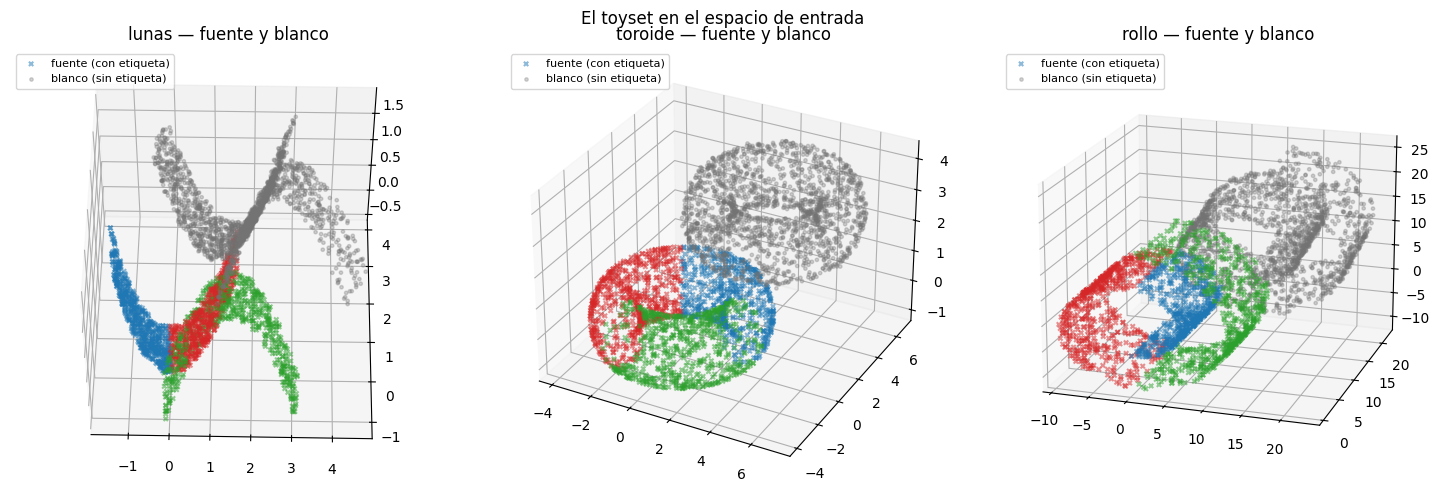

In [8]:
from CREDA.toy_experiment import COL_DURA, VISTA_DURA

ROLES = ("tr", "va", "te")


def input_data(family):
    data = load_data(family)
    return {key: torch.cat([data[f"{key}_{role}"] for role in ROLES]).numpy()
            for key in ("Xs", "ys", "Xt")}


def plot_input_data(inputs):
    figure = plt.figure(figsize=(15, 5))
    for column, (name, data) in enumerate(inputs.items(), 1):
        ax = figure.add_subplot(1, len(inputs), column, projection="3d")
        ax.scatter(*data["Xs"].T, c=[COL_DURA[int(c)] for c in data["ys"]],
                   marker="x", s=10, alpha=0.5, label="fuente (con etiqueta)")
        ax.scatter(*data["Xt"].T, c="0.45", marker="o", s=6, alpha=0.3,
                   label="blanco (sin etiqueta)")
        points = np.concatenate([data["Xs"], data["Xt"]])
        low, high = points.min(0), points.max(0)
        margin = 0.05 * (high - low)
        ax.set_xlim(low[0] - margin[0], high[0] + margin[0])
        ax.set_ylim(low[1] - margin[1], high[1] + margin[1])
        ax.set_zlim(low[2] - margin[2], high[2] + margin[2])
        ax.view_init(*VISTA_DURA[name])
        ax.set_title(f"{name} — fuente y blanco")
        ax.legend(loc="upper left", fontsize=8)
    figure.suptitle("El toyset en el espacio de entrada")
    figure.tight_layout()
    return figure


INPUT_DATA = {family["nombre"]: input_data(family) for family in TUTORIAL_FAMILIES}
INPUT_FIGURE = plot_input_data(INPUT_DATA)
plt.close(INPUT_FIGURE)
INPUT_FIGURE


## `v2` · Fase 1: la fuente sola

Un optimizador Adam sobre **encoder y cabeza**, la CE de la fuente, y parada
temprana: si el acierto en la validación de la fuente no mejora durante
`source_patience` épocas, se corta y se restauran los pesos de la mejor época.
Al salir, todo queda congelado (`requires_grad=False`) y en modo `eval`.

Un lote de un solo punto se salta: BatchNorm no puede estimar una varianza con
una muestra.

In [9]:
def train_source_phase(encoder, head, xs, ys, xs_val, ys_val, config, generator):
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=config["source_lr"])
    batch_size = config["batch_size"]
    history, best_acc, best_epoch, best_state = [], -1.0, -1, None
    for epoch in range(config["source_epochs"]):
        encoder.train()
        head.train()
        order = torch.randperm(len(xs), generator=generator)
        losses = []
        for start in range(0, len(xs), batch_size):
            i = order[start:start + batch_size]
            if len(i) < 2:
                continue
            loss = perdida_fuente(head(encoder(xs[i])), ys[i])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach()))
        val_acc = evaluate(encoder, head, xs_val, ys_val)
        history.append(dict(epoch=epoch, loss=float(np.mean(losses)), source_val_acc=val_acc))
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = ({k: v.clone() for k, v in encoder.state_dict().items()},
                          {k: v.clone() for k, v in head.state_dict().items()})
        if epoch - best_epoch >= config["source_patience"]:
            break
    encoder.load_state_dict(best_state[0])
    head.load_state_dict(best_state[1])
    encoder.eval()
    head.eval()
    for parameter in list(encoder.parameters()) + list(head.parameters()):
        parameter.requires_grad_(False)
    return history

## `v2` · Fase 2: solo el blanco se mueve

El optimizador recibe **solo** `encoder_t.parameters()`. En cada paso:

1. la fuente pasa por el encoder **congelado** de la fuente, bajo `no_grad`;
2. el blanco pasa por `encoder_t`, que es lo único con gradiente;
3. la cabeza congelada lee el latente del blanco y da `g_t = softmax(...)`, las
   pseudo-posteriores que CREDA usa para rutear por clase (también bajo
   `no_grad`: la decisión de clase no es diferenciable);
4. el objetivo es **solo** el término CREDA, con coeficiente 1.

Una época es una pasada completa por el train del blanco; para cada lote del
blanco se sortea un lote de la fuente del mismo tamaño. No hay selección de
época: la fase corre su presupuesto entero y se queda con la última. Se
registran tres cosas sin etiquetas del blanco: el valor del término, cuánto se
alejó `encoder_t` del encoder de la fuente (`parameter_distance`) y el número
efectivo de clases en las predicciones del blanco (`clases_efectivas`, de 1 =
todo colapsado a una clase, a 3 = reparto parejo).

`on_epoch_end`, si se pasa, se llama al cerrar cada época con su número. Es
el gancho por el que más abajo se sacan las fotos del GIF: no entra en el
objetivo, no mueve ningún parámetro y no sortea nada.

In [10]:
def adapt_target(encoder_s, head, encoder_t, xs, ys, xt, config, generator, *, sigma,
                 on_epoch_end=None):
    frozen = list(encoder_s.parameters()) + list(head.parameters())
    if any(p.requires_grad for p in frozen):
        raise ValueError("phase two needs a frozen source encoder and head")
    loss_fn = build_loss(config, sigma=sigma)
    optimizer = torch.optim.Adam(encoder_t.parameters(), lr=config["adaptation_lr"])
    batch_size = config["batch_size"]
    history = []
    for epoch in range(config["adaptation_epochs"]):
        encoder_t.train()
        order = torch.randperm(len(xt), generator=generator)
        terms = []
        for start in range(0, len(xt), batch_size):
            j = order[start:start + batch_size]
            if len(j) < 2:
                continue
            i = torch.randperm(len(xs), generator=generator)[:len(j)]
            with torch.no_grad():
                f_s = encoder_s(xs[i])
            f_t = encoder_t(xt[j])
            with torch.no_grad():
                g_t = F.softmax(head(f_t), dim=1)
            term = loss_fn(f_s, f_t, ys[i], g_t)
            optimizer.zero_grad()
            term.backward()
            optimizer.step()
            terms.append(float(term.detach()))
        encoder_t.eval()
        with torch.no_grad():
            routing = head(encoder_t(xt)).argmax(1)
        history.append(dict(
            epoch=epoch,
            creda=float(np.mean(terms)),
            drift=parameter_distance(encoder_t, encoder_s),
            effective_classes=clases_efectivas(routing),
        ))
        if on_epoch_end is not None:
            on_epoch_end(epoch)
    return history

## `v01` · Un solo entrenamiento conjunto

Un optimizador Adam sobre **encoder y cabeza**, que ven los dos dominios. Por
época: la tasa de aprendizaje sale de `get_eta` y el coeficiente de `creda_ramp`
— cero en la primera época, de modo que esa época es CE pura, y subiendo hacia
el techo después —. Por lote: la CE de la fuente más `λ` por el término CREDA
entre el latente de la fuente y el del blanco. El blanco se recorre en su propio
orden y vuelve a empezar cuando se agota, como el `tgt_loader` publicado.

Como en `train_creda`, no hay selección de época: el modelo final es el de la
última. La validación de la fuente se registra solo para mirarla. El mismo gancho
`on_epoch_end` que en `v2` permite sacar fotos sin tocar el entrenamiento.

In [11]:
def target_batches(xt, batch_size, generator):
    while True:
        order = torch.randperm(len(xt), generator=generator)
        for start in range(0, len(xt), batch_size):
            yield xt[order[start:start + batch_size]]


def train_joint(encoder, head, xs, ys, xt, xs_val, ys_val, config, generator,
                on_epoch_end=None):
    loss_fn = build_loss(config)
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=config["lr"])
    epochs, batch_size = config["epochs"], config["batch_size"]
    target = target_batches(xt, batch_size, generator)
    history = []
    for epoch in range(epochs):
        lam = creda_ramp(epoch, epochs, config["delta"], ceiling=config["lambda_ceiling"])
        lr = get_eta(epoch, epochs, config["alpha"], config["lr"])
        for group in optimizer.param_groups:
            group["lr"] = lr
        encoder.train()
        head.train()
        order = torch.randperm(len(xs), generator=generator)
        rows = []
        for start in range(0, len(xs), batch_size):
            i = order[start:start + batch_size]
            if len(i) < 2:
                continue
            x_t = next(target)
            if len(x_t) < 2:
                x_t = next(target)
            f_s = encoder(xs[i])
            f_t = encoder(x_t)
            ce = F.cross_entropy(head(f_s), ys[i])
            g_t = F.softmax(head(f_t), dim=1)
            creda = loss_fn(f_s, f_t, ys[i], g_t)
            total = ce + lam * creda
            optimizer.zero_grad()
            total.backward()
            optimizer.step()
            rows.append((float(ce.detach()), float(creda.detach()), float(total.detach())))
        ce_mean, creda_mean, total_mean = np.mean(rows, axis=0)
        history.append(dict(
            epoch=epoch, lr=float(lr), **{"lambda": float(lam)},
            ce=float(ce_mean), creda=float(creda_mean), total=float(total_mean),
            source_val_acc=evaluate(encoder, head, xs_val, ys_val),
        ))
        if on_epoch_end is not None:
            on_epoch_end(epoch)
    encoder.eval()
    head.eval()
    return history

## Una familia, de punta a punta

`run_family` encadena las piezas según la versión y devuelve los modelos, las
historias y los aciertos en el **test** de cada dominio. Fija las semillas al
empezar, así que dos llamadas con los mismos datos dan los mismos pesos.

En `v2` reporta también `target_source_only`: el modelo de la fase 1 aplicado
al blanco sin adaptar, la línea base contra la que se lee la fase 2. En `v01`
un único encoder sirve a los dos dominios, así que `encoder_s` y `encoder_t`
son el mismo objeto.

**Las fotos de la trayectoria.** Un `TrajectoryRecorder` guarda, para el test
de cada dominio (360 puntos de cada lado), el latente, la predicción de la
cabeza y la confianza `w` — al inicio y tras unas `FRAMES` épocas repartidas
hasta la última. Pasa los modelos a `eval()` para no tocar los buffers de
BatchNorm, trabaja bajo `no_grad`, no sortea nada y devuelve a cada módulo
el modo que tenía: con fotos o sin ellas (`frames=0`) los pesos finales son
idénticos. No recibe etiquetas; se agregan solo al dibujar. En `v2` la foto
inicial es el modelo de la fase 1 aplicado al blanco; en `v01`, el modelo
recién inicializado.

In [12]:
def run_family(family, config, data=None, frames=None):
    data = load_data(family) if data is None else data
    frames = FRAMES if frames is None else frames
    torch.manual_seed(SEED)
    generator = torch.Generator().manual_seed(SEED)
    encoder, head = new_model(config)
    history, acc = {}, {}
    if config["version"] == "v2":
        history["source"] = train_source_phase(
            encoder, head, data["Xs_tr"], data["ys_tr"], data["Xs_va"], data["ys_va"],
            config, generator)
        with torch.no_grad():
            sigma = sigma_de_la_fuente(encoder(data["Xs_tr"]))
        acc["target_source_only"] = evaluate(encoder, head, data["Xt_te"], data["yt_te"])
        encoder_t = clone_for_target(encoder)
        recorder = TrajectoryRecorder(encoder, encoder_t, head, data["Xs_te"], data["Xt_te"],
                                      epochs=config["adaptation_epochs"], frames=frames)
        recorder.start()
        history["adaptation"] = adapt_target(
            encoder, head, encoder_t, data["Xs_tr"], data["ys_tr"], data["Xt_tr"],
            config, generator, sigma=sigma, on_epoch_end=recorder)
    else:
        recorder = TrajectoryRecorder(encoder, encoder, head, data["Xs_te"], data["Xt_te"],
                                      epochs=config["epochs"], frames=frames)
        recorder.start()
        history["joint"] = train_joint(
            encoder, head, data["Xs_tr"], data["ys_tr"], data["Xt_tr"],
            data["Xs_va"], data["ys_va"], config, generator, on_epoch_end=recorder)
        sigma, encoder_t = None, encoder
    acc["source"] = evaluate(encoder, head, data["Xs_te"], data["ys_te"])
    acc["target"] = evaluate(encoder_t, head, data["Xt_te"], data["yt_te"])
    return dict(encoder_s=encoder, encoder_t=encoder_t, head=head,
                history=history, sigma=sigma, acc=acc, data=data,
                snapshots=recorder.snapshots)

## Las tres familias

Una sola arquitectura y una sola configuración para las tres. Los presupuestos
por defecto están pensados para correr en CPU; si querés ver qué pasa con más
épocas, cambiá `ADJUSTMENTS` arriba y volvé a correr.

In [13]:
RESULTS = {}
for family in TUTORIAL_FAMILIES:
    name = family["nombre"]
    RESULTS[name] = run_family(family, CONFIG)
    line = "  ".join(f"{k}={v:.3f}" for k, v in RESULTS[name]["acc"].items())
    print(f"{CONFIG['version']}  {name:<8} {line}")

v2  lunas    target_source_only=0.464  source=0.900  target=0.533


v2  toroide  target_source_only=0.403  source=0.984  target=0.890


v2  rollo    target_source_only=0.323  source=0.989  target=0.887


## Gráficas

Una fila por familia:

- **izquierda**, la historia del entrenamiento. En `v2`, la CE de la fase 1 y el
  término CREDA de la fase 2 una a continuación de la otra; en `v01`, la CE, el
  término CREDA y el total por época, con `λ` en el eje derecho;
- **centro**, el latente del blanco proyectado a 2D (las dos primeras
  componentes principales) con el encoder final, coloreado por la clase
  verdadera — las etiquetas del blanco se usan acá solo para pintar;
- **derecha**, el acierto en el test de cada dominio.

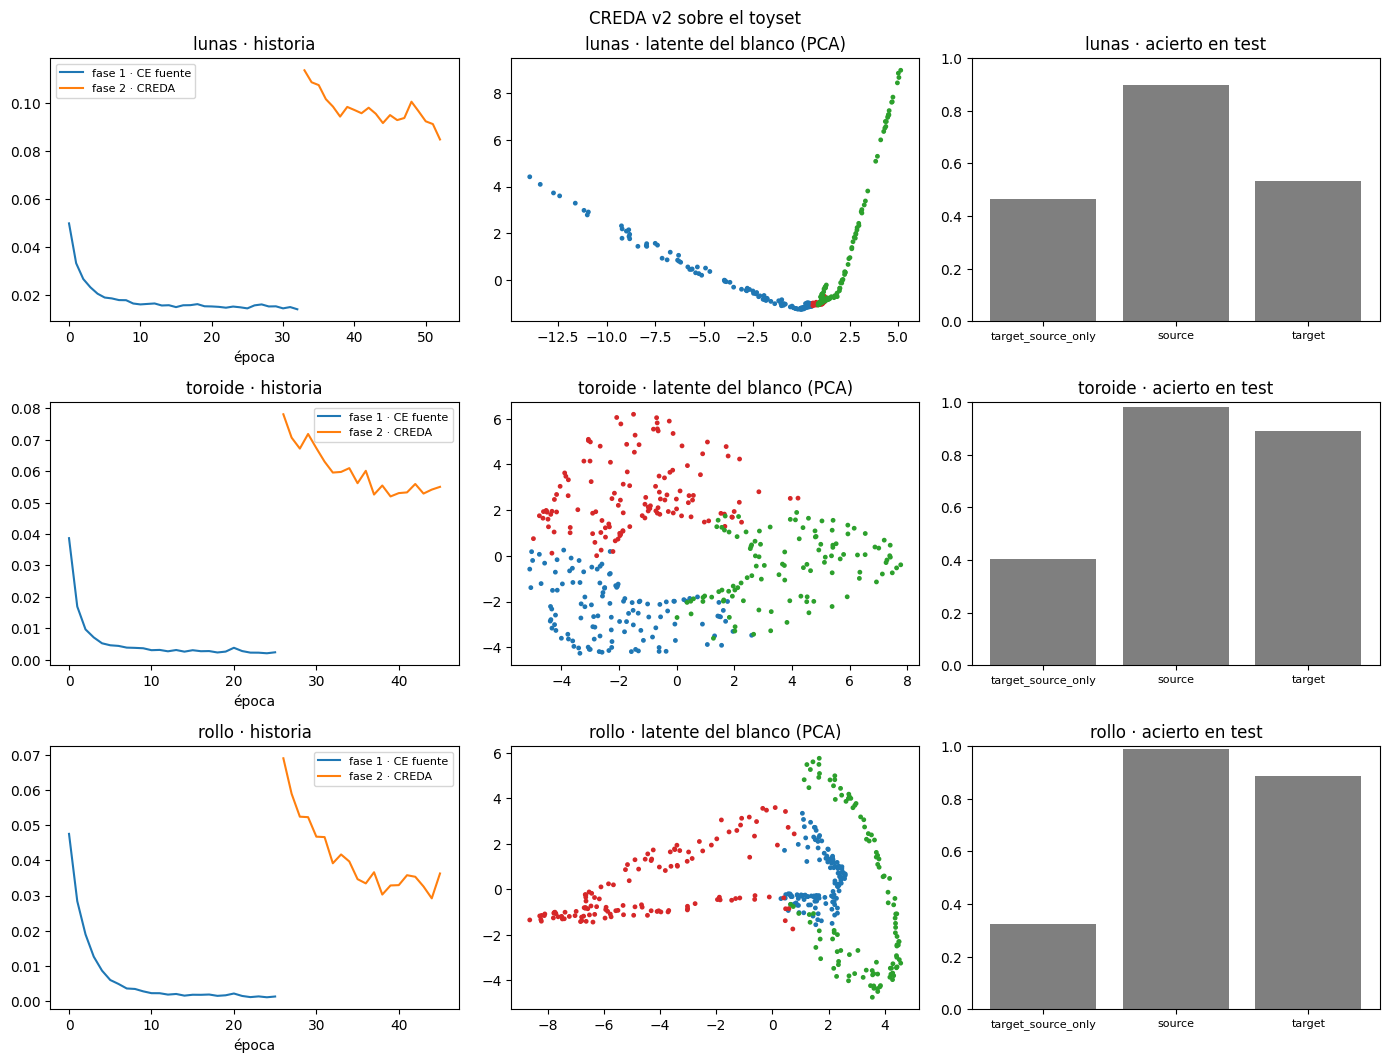

In [14]:
def plot_results(results, config):
    families = list(results)
    figure, axes = plt.subplots(len(families), 3, figsize=(14, 3.6 * len(families)),
                                squeeze=False)
    colors = np.array(["#1f77b4", "#d62728", "#2ca02c"])
    for row, name in zip(axes, families):
        result = results[name]
        history = result["history"]
        if config["version"] == "v2":
            source = [h["loss"] for h in history["source"]]
            adaptation = [h["creda"] for h in history["adaptation"]]
            row[0].plot(range(len(source)), source, label="fase 1 · CE fuente")
            row[0].plot(range(len(source), len(source) + len(adaptation)), adaptation,
                        label="fase 2 · CREDA")
        else:
            joint = history["joint"]
            for key in ("ce", "creda", "total"):
                row[0].plot([h[key] for h in joint], label=key)
            ramp_axis = row[0].twinx()
            ramp_axis.plot([h["lambda"] for h in joint], "k:", label="λ")
            ramp_axis.set_ylabel("λ")
        row[0].set_title(f"{name} · historia")
        row[0].set_xlabel("época")
        row[0].legend(fontsize=8)

        with torch.no_grad():
            latent = result["encoder_t"](result["data"]["Xt_te"]).numpy()
        centered = latent - latent.mean(0)
        _, _, components = np.linalg.svd(centered, full_matrices=False)
        projected = centered @ components[:2].T
        row[1].scatter(projected[:, 0], projected[:, 1], s=6,
                       c=colors[result["data"]["yt_te"].numpy()])
        row[1].set_title(f"{name} · latente del blanco (PCA)")

        labels = list(result["acc"])
        row[2].bar(labels, [result["acc"][k] for k in labels], color="#7f7f7f")
        row[2].set_ylim(0, 1)
        row[2].set_title(f"{name} · acierto en test")
        row[2].tick_params(axis="x", labelsize=8)
    figure.suptitle(f"CREDA {config['version']} sobre el toyset")
    figure.tight_layout()
    return figure


FIGURE = plot_results(RESULTS, CONFIG)
plt.close(FIGURE)
FIGURE

## La adaptación, cuadro a cuadro

Un GIF por familia, armado con las fotos **reales** de la trayectoria: cada
cuadro es el modelo tal como estaba al inicio o al cerrar una época, no una
interpolación entre el primero y el último.

- **izquierda**, el latente del test de cada dominio — `x` fuente, `o` blanco —
  coloreado por la clase **verdadera**, con el centro de cada clase (◇ fuente,
  ◆ blanco). Alinear es que los ◆ caigan sobre los ◇ de su misma clase;
- **centro**, los mismos puntos coloreados por la **predicción** de la cabeza,
  con el tamaño proporcional a la confianza `w` (la de la Ec. 24, abajo);
- **derecha**, el acierto de cada dominio y la `w` media del blanco sobre esos
  mismos puntos, época a época.

La proyección es **una sola** para todos los cuadros: el PCA del latente de la
fuente en la primera foto, con ejes fijos. Así lo que se mueve entre cuadros es
el latente y no los ejes. En `v2` la fuente y la cabeza están congeladas y solo
se mueve el blanco; en `v01` se mueven las dos nubes y también la cabeza, y la
base de la proyección es la del modelo recién inicializado. Las etiquetas del
blanco solo pintan y miden: el entrenamiento no las vio.

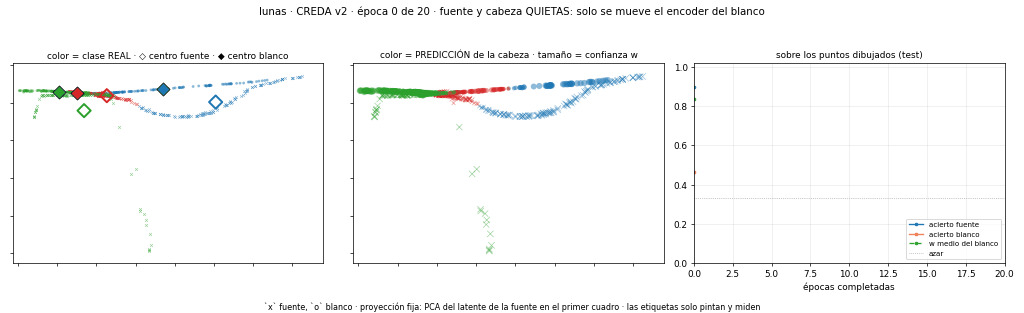

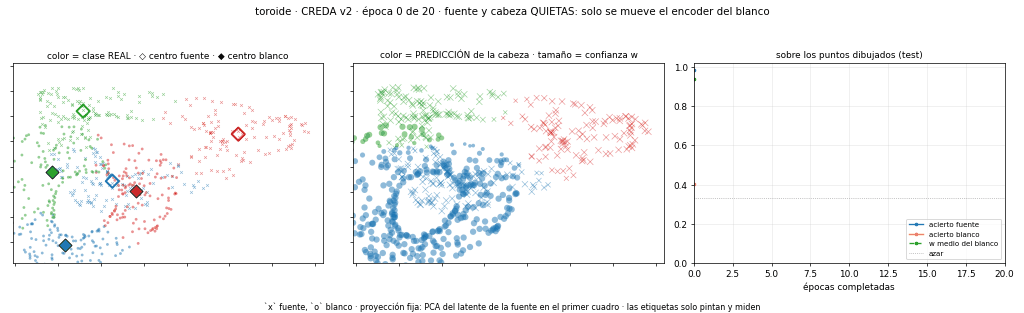

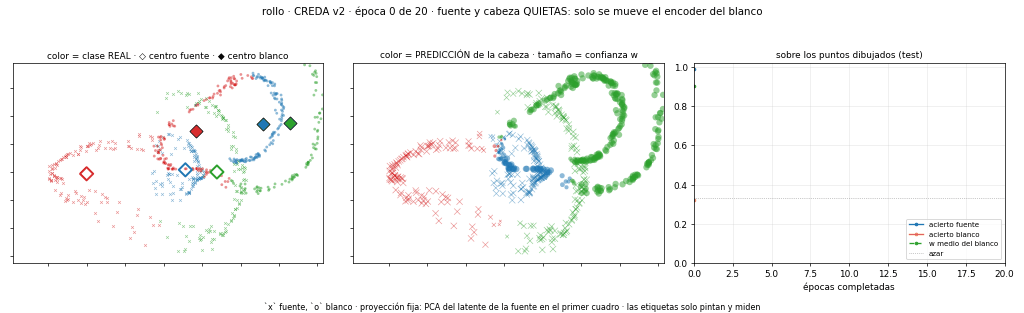

In [15]:
ADAPTATION_GIFS = {}
epochs = CONFIG["adaptation_epochs"] if CONFIG["version"] == "v2" else CONFIG["epochs"]
for name, result in RESULTS.items():
    ADAPTATION_GIFS[name] = adaptation_gif(
        name, result["snapshots"], result["data"]["ys_te"].numpy(),
        result["data"]["yt_te"].numpy(), version=CONFIG["version"], epochs=epochs)
    display(Image(data=ADAPTATION_GIFS[name], format="gif"))

## Qué hace el peso `w`

CREDA pondera cada punto del blanco por su **confianza**,

$$w = 1 - \frac{\hat H_2(g)}{\ln C}, \qquad \hat H_2(g) = -\ln \sum_c g_c^2,$$

la Ec. 24, calculada por la misma función que usa `CREDALoss`
(`MIL_CREDA.confidence.confidences`). `w` depende solo del posterior `g` de la
cabeza: mide **confianza, no acierto**.

Esta animación es **construida, no medida**. En el latente de la fuente — el
que produce el encoder entrenado — se toman tres arranques que la cabeza
entrenada resuelve exactamente: dos fronteras **dobles** (dos clases empatan y
la tercera no pesa: `w = 1 − ln 2 / ln 3 ≈ 0.369`) y la frontera **triple** (las
tres empatan: `w ≈ 0`). Cada punto camina en línea recta hasta el centro de una
clase de la fuente, y `w` se lee con la cabeza en cada paso. El eje es un
**barrido** a lo largo de ese camino, no una época ni un paso del optimizador.

Dónde termina cada curva depende de la geometría que dejó el entrenamiento: si
el centro de la clase queda bien adentro de su región, `w` llega cerca de 1; si
queda cerca de otra frontera, se queda más abajo. En `v01` la cabeza también se
entrenó con el blanco, así que estas fronteras son las de la cabeza conjunta
final. Si una frontera no pudiera aislarse con esta cabeza, la celda lo dice
en lugar de dibujar un camino inventado.

lunas    1. frontera 0|1 → centro 0  w: 0.369 → 1.000
lunas    2. frontera 1|2 → centro 2  w: 0.369 → 0.983
lunas    3. frontera 0|1|2 → centro 1  w: 0.000 → 0.514


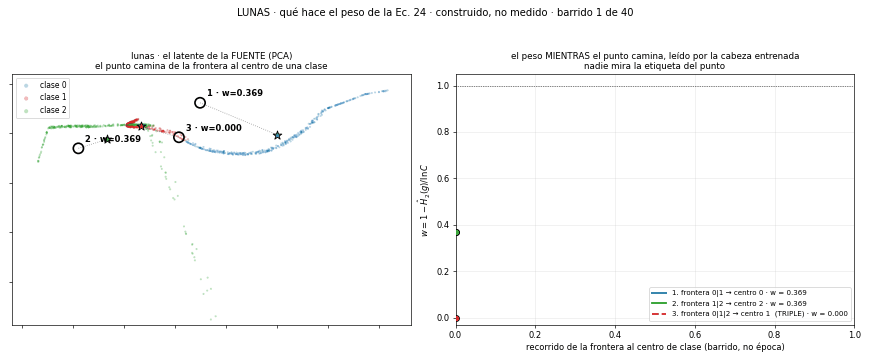

toroide  1. frontera 0|1 → centro 0  w: 0.369 → 0.999
toroide  2. frontera 1|2 → centro 2  w: 0.369 → 0.998
toroide  3. frontera 0|1|2 → centro 1  w: 0.000 → 0.999


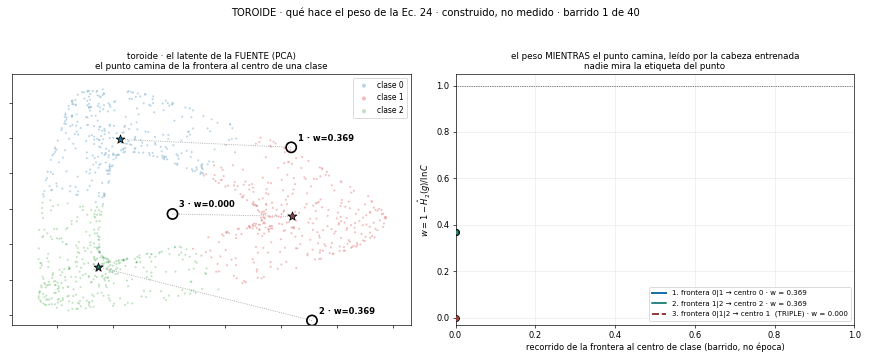

rollo    1. frontera 0|1 → centro 0  w: 0.369 → 0.980
rollo    2. frontera 1|2 → centro 2  w: 0.369 → 0.974
rollo    3. frontera 0|1|2 → centro 1  w: 0.000 → 0.999


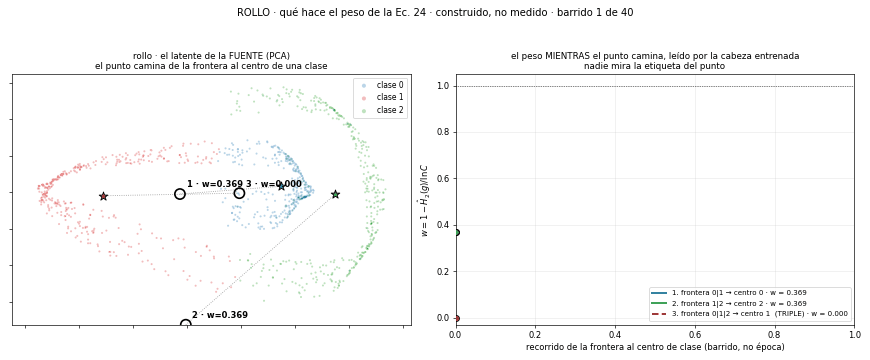

In [16]:
WALKS, WALK_GIFS = {}, {}
for name, result in RESULTS.items():
    result["encoder_s"].eval()
    with torch.no_grad():
        latent = result["encoder_s"](result["data"]["Xs_tr"]).numpy()
    ys = result["data"]["ys_tr"].numpy()
    try:
        WALKS[name] = confidence_walks(latent, ys, result["head"], WALK_STEPS)
    except ValueError as reason:
        print(f"{name}: con esta cabeza no se puede aislar una frontera: {reason}")
        continue
    for i, path in enumerate(WALKS[name], 1):
        tie = "|".join(map(str, path["classes"]))
        print(f"{name:<8} {i}. frontera {tie} → centro {path['destination']}  "
              f"w: {path['w'][0]:.3f} → {path['w'][-1]:.3f}")
    WALK_GIFS[name] = confidence_walk_gif(name, latent, ys, WALKS[name])
    display(Image(data=WALK_GIFS[name], format="gif"))

## Cómo leer lo que salió

- **Presupuesto corto contra convergencia.** Con los valores por defecto la
  fase 1 puede parar antes por paciencia y la fase 2 corre solo
  `adaptation_epochs` pasadas. Eso alcanza para ver el flujo completo y la forma
  de las curvas, no para afirmar que el método convergió ni para comparar
  versiones: para eso hacen falta más épocas, varias semillas y una selección
  de hiperparámetros declarada de antemano, que este cuaderno no hace.
- **Una sola semilla.** Cada número de arriba es una corrida. La diferencia
  entre dos números de una corrida no es una medición de nada.
- **Las etiquetas del blanco no entrenan.** Ninguna función de entrenamiento las
  recibe; se leen solo para el acierto final y para colorear el latente.
- **Los GIF no son resultados aparte.** El de la adaptación muestra la
  trayectoria de **esta** corrida; el de `w` es una propiedad de la Ec. 24 y de
  la cabeza entrenada, leída sobre caminos construidos.
- **Para cambiar de versión**, poné `VERSION = "v01"` en la celda de parámetros
  y corré todo de nuevo. Cualquier valor que no sea `"v2"` ni `"v01"` se rechaza.